# Assignment 2

## Set up

In [45]:
import pandas as pd
import numpy as np
from pathlib import Path
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option("display.max_columns", 25)
pd.set_option("display.max_rows", 12)

print("pandas version:", pd.__version__)

pandas version: 2.2.3


## Question 1

### Stage 1: Ingest

In [46]:
local_path_q1 = Path("data/raw_train.csv")
data_url_q1 = "https://raw.githubusercontent.com/katreenadinh/CS5530_Assignment2/refs/heads/main/data_raw/raw_train.csv"
source_q1 = local_path_q1 if local_path_q1.exists() else data_url_q1
df_raw_q1 = pd.read_csv(source_q1)

print(f"Loaded {df_raw_q1.shape[0]} rows and {df_raw_q1.shape[1]} columns from {source_q1}")

Loaded 5847 rows and 14 columns from https://raw.githubusercontent.com/katreenadinh/CS5530_Assignment2/refs/heads/main/data_raw/raw_train.csv


### Stage 2: Process

In [47]:
df_raw_q1.head()

,Unnamed: 0,Name,Location,Year,Kilometers_Driven,Fuel_Type,Transmission,Owner_Type,Mileage,Engine,Power,Seats,New_Price,Price
0,1,Hyundai Creta 1.6 CRDi SX Option,Pune,2015,41000,Diesel,Manual,First,19.67 kmpl,1582 CC,126.2 bhp,5.0,NaN,12.50
1,2,Honda Jazz V,Chennai,2011,46000,Petrol,Manual,First,13 km/kg,1199 CC,88.7 bhp,5.0,8.61 Lakh,4.50
2,3,Maruti Ertiga VDI,Chennai,2012,87000,Diesel,Manual,First,20.77 kmpl,1248 CC,88.76 bhp,7.0,NaN,6.00
3,4,Audi A4 New 2.0 TDI Multitronic,Coimbatore,2013,40670,Diesel,Automatic,Second,15.2 kmpl,1968 CC,140.8 bhp,5.0,NaN,17.74
4,6,Nissan Micra Diesel XV,Jaipur,2013,86999,Diesel,Manual,First,23.08 kmpl,1461 CC,63.1 bhp,5.0,NaN,3.50


In [48]:
df_raw_q1.shape

(5847, 14)

In [49]:
# create copy of df
df_clean_q1 = df_raw_q1.copy()

#### b. Remove units

In [50]:
# checking what units are in each columns
print(df_clean_q1["Mileage"].dropna().str.extract(r"([A-Za-z/]+)$")[0].value_counts(), "\n")

print(df_clean_q1["Engine"].dropna().str.extract(r"([A-Za-z/]+)$")[0].value_counts(), "\n")

print(df_clean_q1["Power"].dropna().str.extract(r"([A-Za-z/]+)$")[0].value_counts(), "\n")

print(df_clean_q1["New_Price"].dropna().str.extract(r"([A-Za-z/]+)$")[0].value_counts(), "\n")


0
kmpl     5842
km/kg       3
Name: count, dtype: int64 

0
CC    5811
Name: count, dtype: int64 

0
bhp    5811
Name: count, dtype: int64 

0
Lakh    798
Cr       17
Name: count, dtype: int64 



In [51]:
# removing units from mileage, engine, and power
df_clean_q1["Mileage"] = df_clean_q1["Mileage"].str.extract(r"([\d.]+)")[0].astype(float)
df_clean_q1["Engine"]  = df_clean_q1["Engine"].str.extract(r"([\d.]+)")[0].astype(float)
df_clean_q1["Power"]   = df_clean_q1["Power"].str.extract(r"([\d.]+)")[0].astype(float)


In [52]:
# handling conversion and unit for new_price

np_num = df_clean_q1["New_Price"].str.extract(r"([\d.]+)")[0].astype(float)
is_cr  = df_clean_q1["New_Price"].str.contains("Cr", na=False)
df_clean_q1["New_Price"] = np.where(is_cr, np_num * 100, np_num)

#### a. Missing Values and Imputing


In [53]:
df_raw_q1.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5847 entries, 0 to 5846
Data columns (total 14 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   Unnamed: 0         5847 non-null   int64  
 1   Name               5847 non-null   object 
 2   Location           5847 non-null   object 
 3   Year               5847 non-null   int64  
 4   Kilometers_Driven  5847 non-null   int64  
 5   Fuel_Type          5847 non-null   object 
 6   Transmission       5847 non-null   object 
 7   Owner_Type         5847 non-null   object 
 8   Mileage            5845 non-null   object 
 9   Engine             5811 non-null   object 
 10  Power              5811 non-null   object 
 11  Seats              5809 non-null   float64
 12  New_Price          815 non-null    object 
 13  Price              5847 non-null   float64
dtypes: float64(2), int64(3), object(9)
memory usage: 639.6+ KB


In [54]:
# Check for missing values and duplicates

print("Total missing values per column:")
print(df_raw_q1.isnull().sum())

print("\nNumber of duplicate rows:")
print(df_raw_q1.duplicated().sum())

Total missing values per column:
Unnamed: 0              0
Name                    0
Location                0
Year                    0
Kilometers_Driven       0
                     ... 
Engine                 36
Power                  36
Seats                  38
New_Price            5032
Price                   0
Length: 14, dtype: int64

Number of duplicate rows:
0


In [55]:
missing_summary = pd.DataFrame({
    "missing_count": df_raw_q1.isna().sum(),
    "missing_percent": df_raw_q1.isna().mean().mul(100).round(2),
})

missing_summary.query("missing_count > 0").sort_values(
    "missing_percent", ascending=False
)

,missing_count,missing_percent
New_Price,5032,86.06
Seats,38,0.65
Power,36,0.62
Engine,36,0.62
Mileage,2,0.03


In [56]:
# Find where columns have 0 values and amount
zeros = (df_clean_q1 == 0).sum()
zeros[zeros > 0]

,0
Mileage,40


In [57]:
df_clean_q1[df_clean_q1["Mileage"] == 0]

,Unnamed: 0,Name,Location,Year,Kilometers_Driven,Fuel_Type,Transmission,Owner_Type,Mileage,Engine,Power,Seats,New_Price,Price
12,14,Land Rover Freelander 2 TD4 SE,Pune,2012,85000,Diesel,Automatic,Second,0.0,2179.0,115.00,5.0,NaN,17.50
65,67,Mercedes-Benz C-Class Progressive C 220d,Coimbatore,2019,15369,Diesel,Automatic,First,0.0,1950.0,194.00,5.0,49.14,35.67
186,194,Honda City 1.5 GXI,Ahmedabad,2007,60006,Petrol,Manual,First,0.0,NaN,NaN,NaN,NaN,2.95
220,229,Ford Figo Diesel,Bangalore,2015,70436,Diesel,Manual,First,0.0,1498.0,99.00,NaN,NaN,3.60
524,544,Mercedes-Benz New C-Class Progressive C 200,Kochi,2019,13190,Petrol,Automatic,First,0.0,1950.0,181.43,5.0,49.49,38.99
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
5162,5311,Land Rover Freelander 2 TD4 SE,Hyderabad,2012,139000,Diesel,Automatic,First,0.0,2179.0,115.00,5.0,NaN,16.75
5225,5374,Mercedes-Benz M-Class ML 350 4Matic,Ahmedabad,2012,66000,Diesel,Automatic,First,0.0,2987.0,165.00,5.0,NaN,23.00
5712,5875,Mercedes-Benz C-Class Progressive C 220d,Ahmedabad,2019,4000,Diesel,Automatic,First,0.0,1950.0,194.00,5.0,49.14,35.00
5802,5972,Hyundai Santro Xing GL,Mumbai,2008,65000,Petrol,Manual,Second,0.0,1086.0,62.00,5.0,NaN,1.39


In [58]:
# drop new_price
df_clean_q1 = df_clean_q1.drop(columns="New_Price")

# replace mileage value 0 with NaN
df_clean_q1["Mileage"] = df_clean_q1["Mileage"].replace(0, np.nan)

# impute medians for mileage, engine, power, and seats
for col in ["Mileage", "Engine", "Power", "Seats"]:
    df_clean_q1[col] = df_clean_q1[col].fillna(df_clean_q1[col].median())

Justification:

* New_Price: Dropped because 86% of the column's values were missing. Imputation was avoided to prevent introducing inaccurate values that could distort relationships with other columns.
* Mileage: Imputed zero and missing values with the median because mileage cannot be zero and the median is more robust than the mean.
* Engine: Imputed missing values with the median because it is more robust than the mean.
* Power: Imputed missing values with the median because it is more robust than the mean.
* Seats: Imputed missing values with the median because it is more robust than the mean.




In [59]:
# check for any missing values again
missing_summary = pd.DataFrame({
    "missing_count": df_clean_q1.isna().sum(),
    "missing_percent": df_clean_q1.isna().mean().mul(100).round(2),
})

missing_summary.query("missing_count > 0").sort_values(
    "missing_percent", ascending=False
)

,missing_count,missing_percent


In [60]:
# check for any 0 values again
print("Mileage zeros:", (df_clean_q1["Mileage"] == 0).sum())

Mileage zeros: 0


#### C. Categorical -> Numerical One Hot Encoded

In [61]:
# Fuel Type
df_clean_q1["Fuel_Type"].unique()
df_clean_q1 = pd.get_dummies(df_clean_q1, columns=["Fuel_Type"], dtype=int)

In [62]:
# Transmisson
df_clean_q1["Transmission"].unique()
df_clean_q1 = pd.get_dummies(df_clean_q1, columns=["Transmission"], dtype=int)

In [63]:
# Display new columns for fuel type and transmission
df_clean_q1.filter(regex="^(Fuel_Type|Transmission)_").head()

,Fuel_Type_Diesel,Fuel_Type_Electric,Fuel_Type_Petrol,Transmission_Automatic,Transmission_Manual
0,1,0,0,0,1
1,0,0,1,0,1
2,1,0,0,0,1
3,1,0,0,1,0
4,1,0,0,0,1


#### D. Create a feature

In [64]:
CURRENT_YEAR = 2026
df_clean_q1["Car_Age"] = CURRENT_YEAR - df_clean_q1["Year"]

df_clean_q1[["Name", "Year", "Car_Age"]].head()

,Name,Year,Car_Age
0,Hyundai Creta 1.6 CRDi SX Option,2015,11
1,Honda Jazz V,2011,15
2,Maruti Ertiga VDI,2012,14
3,Audi A4 New 2.0 TDI Multitronic,2013,13
4,Nissan Micra Diesel XV,2013,13


#### E. Select, filter, rename, mutate, arrange, & summarize

In [65]:
# Select
df_clean_q1[["Name", "Location", "Kilometers_Driven", "Year", "Car_Age"]].head()

,Name,Location,Kilometers_Driven,Year,Car_Age
0,Hyundai Creta 1.6 CRDi SX Option,Pune,41000,2015,11
1,Honda Jazz V,Chennai,46000,2011,15
2,Maruti Ertiga VDI,Chennai,87000,2012,14
3,Audi A4 New 2.0 TDI Multitronic,Coimbatore,40670,2013,13
4,Nissan Micra Diesel XV,Jaipur,86999,2013,13


In [66]:
# Filter
age_15_or_more = df_clean_q1[df_clean_q1["Car_Age"] >= 15]
age_15_or_more[["Name", "Year", "Kilometers_Driven"]].head()

,Name,Year,Kilometers_Driven
1,Honda Jazz V,2011,46000
21,Hyundai i20 1.2 Magna,2010,45807
22,Volkswagen Vento Petrol Highline AT,2010,33000
27,Toyota Innova 2.5 V Diesel 7-seater,2007,262000
31,Audi A6 2.7 TDI,2010,35000


In [67]:
# Rename
df_clean_q1 = df_clean_q1.rename(columns={
    "Price": "Price_Lakh",
    "Power": "Power_bhp",
    "Engine": "Engine_cc"
})

In [68]:
# Mutate
df_clean_q1["Price_Per_Year"] = df_clean_q1["Price_Lakh"] / df_clean_q1["Car_Age"]

In [69]:
# Arrange
df_clean_q1.sort_values(["Price_Lakh", "Car_Age"], ascending=[False, True])

,Unnamed: 0,Name,Location,Year,Kilometers_Driven,Owner_Type,Mileage,Engine_cc,Power_bhp,Seats,Price_Lakh,Fuel_Type_Diesel,Fuel_Type_Electric,Fuel_Type_Petrol,Transmission_Automatic,Transmission_Manual,Car_Age,Price_Per_Year
3952,4079,Land Rover Range Rover 3.0 Diesel LWB Vogue,Hyderabad,2017,25000,First,13.33,2993.0,255.0,5.0,160.00,1,0,0,1,0,9,17.777778
5620,5781,Lamborghini Gallardo Coupe,Delhi,2011,6500,Third,6.40,5204.0,560.0,2.0,120.00,0,0,1,1,0,15,8.000000
5752,5919,Jaguar F Type 5.0 V8 S,Hyderabad,2015,8000,First,12.50,5000.0,488.1,2.0,100.00,0,0,1,1,0,11,9.090909
1457,1505,Land Rover Range Rover Sport SE,Kochi,2019,26013,First,12.65,2993.0,255.0,5.0,97.07,1,0,0,1,0,7,13.867143
1917,1974,BMW 7 Series 740Li,Coimbatore,2018,28060,First,12.05,2979.0,320.0,5.0,93.67,0,0,1,1,0,8,11.708750
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
3127,3228,Maruti 800 Std,Pune,2003,52000,First,16.10,796.0,37.0,4.0,0.50,0,0,1,0,1,23,0.021739
2758,2847,Hyundai Getz GLS,Pune,2005,86000,Second,15.30,1341.0,83.0,5.0,0.45,0,0,1,0,1,21,0.021429
1577,1628,Maruti 800 Std BSIII,Jaipur,2004,12000,Second,16.10,796.0,37.0,4.0,0.45,0,0,1,0,1,22,0.020455
3039,3138,Maruti Zen LXI,Jaipur,1998,95150,Third,17.30,993.0,60.0,5.0,0.45,0,0,1,0,1,28,0.016071


In [70]:
# Summarize w/ group by
by_fuel = (
    df_clean_q1.groupby("Fuel_Type_Diesel")
    .agg(
        num_listings=("Mileage", "size"),
        avg_mileage=("Mileage", "mean"),
        median_mileage=("Mileage", "median"),
        avg_age=("Car_Age", "mean"),
        avg_km=("Kilometers_Driven", "mean")
    )
    .round(2)
)

display(by_fuel)

,num_listings,avg_mileage,median_mileage,avg_age,avg_km
Fuel_Type_Diesel,,,,,
0,2686,17.71,17.92,12.95,47754.90
1,3161,18.77,19.01,12.21,67464.22


#### Additional Cleaning

In [71]:
df_clean_q1 = df_clean_q1.drop(columns="Unnamed: 0")

#### View Final Data

In [72]:
df_clean_q1

,Name,Location,Year,Kilometers_Driven,Owner_Type,Mileage,Engine_cc,Power_bhp,Seats,Price_Lakh,Fuel_Type_Diesel,Fuel_Type_Electric,Fuel_Type_Petrol,Transmission_Automatic,Transmission_Manual,Car_Age,Price_Per_Year
0,Hyundai Creta 1.6 CRDi SX Option,Pune,2015,41000,First,19.67,1582.0,126.20,5.0,12.50,1,0,0,0,1,11,1.136364
1,Honda Jazz V,Chennai,2011,46000,First,13.00,1199.0,88.70,5.0,4.50,0,0,1,0,1,15,0.300000
2,Maruti Ertiga VDI,Chennai,2012,87000,First,20.77,1248.0,88.76,7.0,6.00,1,0,0,0,1,14,0.428571
3,Audi A4 New 2.0 TDI Multitronic,Coimbatore,2013,40670,Second,15.20,1968.0,140.80,5.0,17.74,1,0,0,1,0,13,1.364615
4,Nissan Micra Diesel XV,Jaipur,2013,86999,First,23.08,1461.0,63.10,5.0,3.50,1,0,0,0,1,13,0.269231
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
5842,Maruti Swift VDI,Delhi,2014,27365,First,28.40,1248.0,74.00,5.0,4.75,1,0,0,0,1,12,0.395833
5843,Hyundai Xcent 1.1 CRDi S,Jaipur,2015,100000,First,24.40,1120.0,71.00,5.0,4.00,1,0,0,0,1,11,0.363636
5844,Mahindra Xylo D4 BSIV,Jaipur,2012,55000,Second,14.00,2498.0,112.00,8.0,2.90,1,0,0,0,1,14,0.207143
5845,Maruti Wagon R VXI,Kolkata,2013,46000,First,18.90,998.0,67.10,5.0,2.65,0,0,1,0,1,13,0.203846


In [73]:
# save the cleaned data to csv
df_clean_q1.to_csv("clean_train.csv", index=False)

## Question 2

### Stage 1: Ingest

In [74]:
local_path_q2 = Path("data/raw_diabetes.csv")
data_url_q2 = "https://raw.githubusercontent.com/katreenadinh/CS5530_Assignment2/refs/heads/main/data_raw/raw_diabetes.csv"

source_q2 = local_path_q2 if local_path_q2.exists() else data_url_q2
df_raw_q2 = pd.read_csv(source_q2)

print(f"Loaded {df_raw_q2.shape[0]} rows and {df_raw_q2.shape[1]} columns from {source_q2}")


Loaded 768 rows and 9 columns from https://raw.githubusercontent.com/katreenadinh/CS5530_Assignment2/refs/heads/main/data_raw/raw_diabetes.csv


### Stage 2: Process

In [75]:
df_raw_q2.head()

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1


In [76]:
df_raw_q2.shape

(768, 9)

In [77]:
df_raw_q2.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 768 entries, 0 to 767
Data columns (total 9 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Pregnancies               768 non-null    int64  
 1   Glucose                   768 non-null    int64  
 2   BloodPressure             768 non-null    int64  
 3   SkinThickness             768 non-null    int64  
 4   Insulin                   768 non-null    int64  
 5   BMI                       768 non-null    float64
 6   DiabetesPedigreeFunction  768 non-null    float64
 7   Age                       768 non-null    int64  
 8   Outcome                   768 non-null    int64  
dtypes: float64(2), int64(7)
memory usage: 54.1 KB


In [78]:
# Check for missing values and duplicates

print("Total missing values per column:")
print(df_raw_q2.isnull().sum())

print("\nNumber of duplicate rows:")
print(df_raw_q2.duplicated().sum())

Total missing values per column:
Pregnancies                 0
Glucose                     0
BloodPressure               0
SkinThickness               0
Insulin                     0
BMI                         0
DiabetesPedigreeFunction    0
Age                         0
Outcome                     0
dtype: int64

Number of duplicate rows:
0


In [79]:
df_clean_q2 = df_raw_q2.copy()

In [80]:
# save the cleaned data to csv
df_clean_q2.to_csv("clean_diabetes.csv", index=False)

### Stage 3: Analysis

In [81]:
# set seed
seed = 42
np.random.seed(seed)

#### A. Glucose

In [82]:
sample25 = df_clean_q2.sample(n=25, random_state=seed)

sample_mean = sample25["Glucose"].mean()
sample_max = sample25["Glucose"].max()

population_mean = df_clean_q2["Glucose"].mean()
population_max = df_clean_q2["Glucose"].max()

print("Sample Mean:", round(sample_mean, 2))
print("Population Mean:", round(population_mean, 2))

print("Sample Maximum:", round(sample_max, 2))
print("Population Maximum:", round(population_max, 2))

Sample Mean: 116.64
Population Mean: 120.89
Sample Maximum: 183
Population Maximum: 199


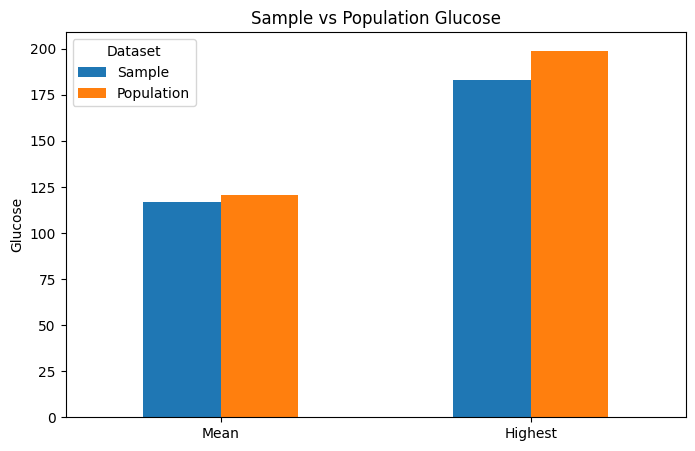

In [83]:
# Chart
glucose_comparison = pd.DataFrame({
    "Sample": [sample_mean, sample_max],
    "Population": [population_mean, population_max]
}, index=["Mean", "Highest"])

glucose_comparison.plot(kind="bar", figsize=(8, 5))

plt.title("Sample vs Population Glucose")
plt.ylabel("Glucose")
plt.xticks(rotation=0)
plt.legend(title="Dataset")
plt.savefig("glucose_comparison.png", dpi=300, bbox_inches="tight")
plt.show()

Findings:

The sample mean was 116.64, while the population mean was 120.89. The sample maximum was 120.89, compared to the population maximum of 199. Overall, both the sample mean and maximum are relatively close to their corresponding population values. The largest difference is between the sample and population maximums, which makes sense because a sample of only 25 observations may not include the population's highest value.

#### B. BMI

In [84]:
sample_bmi_98 = sample25["BMI"].quantile(0.98)

population_bmi_98 = df_clean_q2["BMI"].quantile(0.98)

print("Sample 98th Percentile:", round(sample_bmi_98, 2))
print("Population 98th Percentile:", round(population_bmi_98, 2))

Sample 98th Percentile: 40.25
Population 98th Percentile: 47.53


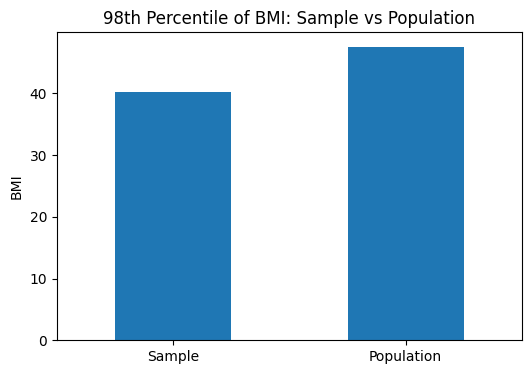

In [85]:
# chart
bmi_comparison = pd.Series({
    "Sample": sample_bmi_98,
    "Population": population_bmi_98
})

bmi_comparison.plot(kind="bar", figsize=(6, 4))

plt.title("98th Percentile of BMI: Sample vs Population")
plt.ylabel("BMI")
plt.xticks(rotation=0)
plt.savefig("bmi_comparison.png", dpi=300, bbox_inches="tight")
plt.show()

Findings:

The sample and population 98th percentiles are also relatively close. The sample's 98th percentile was 40.25, while the population's was 47.53. However, the difference is slightly larger, likely due to the smaller sample size of 25.

#### C. Bootstrap for BloodPressure

In [86]:
# Bootstrapping
bootstrap_means = []
bootstrap_stds = []
bootstrap_percentiles = []

for i in range(500):
    boot_sample = df_clean_q2.sample(n=150, replace=True)
    bootstrap_means.append(boot_sample["BloodPressure"].mean())
    bootstrap_stds.append(boot_sample["BloodPressure"].std())
    bootstrap_percentiles.append(boot_sample["BloodPressure"].quantile(0.98))

avg_boot_mean = np.mean(bootstrap_means)
avg_boot_std = np.mean(bootstrap_stds)
avg_boot_percentile = np.mean(bootstrap_percentiles)

print("Average Bootstrap Mean:", round(avg_boot_mean, 2))
print("Average Bootstrap Std:", round(avg_boot_std, 2))
print("Average Bootstrap 98th Percentile:", round(avg_boot_percentile, 2))

Average Bootstrap Mean: 69.18
Average Bootstrap Std: 19.07
Average Bootstrap 98th Percentile: 97.9


In [87]:
# Population
population_mean = df_clean_q2["BloodPressure"].mean()
population_std = df_clean_q2["BloodPressure"].std()
population_percentile = df_clean_q2["BloodPressure"].quantile(0.98)

print("Population Mean:", round(population_mean, 2))
print("Population Std:", round(population_std, 2))
print("Population 98th Percentile:", round(population_percentile, 2))

Population Mean: 69.11
Population Std: 19.36
Population 98th Percentile: 99.32


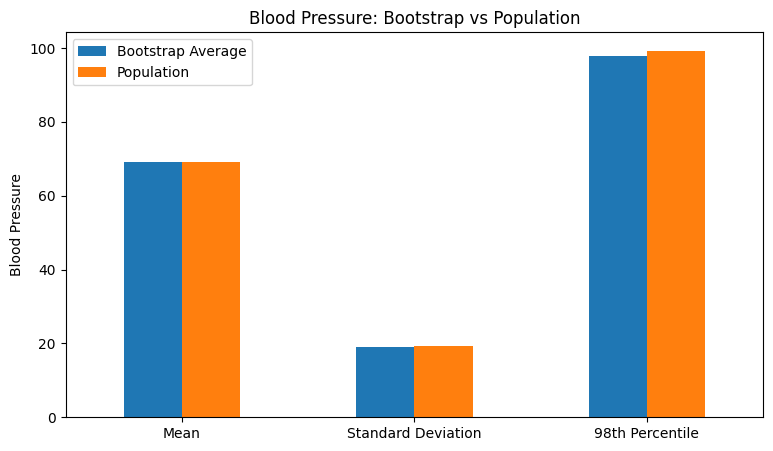

In [88]:
# Chart
bp_comparison = pd.DataFrame({
    "Bootstrap Average": [
        avg_boot_mean,
        avg_boot_std,
        avg_boot_percentile
    ],
    "Population": [
        population_mean,
        population_std,
        population_percentile
    ]
}, index=["Mean", "Standard Deviation", "98th Percentile"])

bp_comparison.plot(kind="bar", figsize=(9, 5))

plt.title("Blood Pressure: Bootstrap vs Population")
plt.ylabel("Blood Pressure")
plt.xticks(rotation=0)
plt.savefig("bloodpressure_bootstrap_comparison.png", dpi=300, bbox_inches="tight")
plt.show()

Findings:

The bootstrap averages were very close to the population statistics. The average bootstrap mean was 69.18 compared to the population mean of 69.11. The standard deviation and 98th percentile were also close to their population values. Overall, the 500 bootstrap samples of 150 observations each produced results that were very close to the population statistics.